# Unsupervised Model Transfer Between Temperature-Modulated MOX Gas Sensors

The study uses eight sensors under shared exposures, with 37 substance classes.
Adaptation uses unlabeled resistance statistics; labels are used for source training,
evaluation, and selecting class subsets in the controlled coverage experiment.
Source scores are training scores, and the eight transfer directions share sensors
and recordings. These are transductive results, not independent-session or online tests.

## 1. Setup and input data

Load `bme_690_all_nuts.csv`, `bme_690_all_spices.csv`, and
`bme_690_all_herbs.csv` from `smell_project/BME690_data/2026collection`.

Leave `DATA_DIR = None` to locate those files in this repository, or set it to
`Path("/path/to/2026collection")`. The version display below records the active
numerical-library versions.

In [2]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

DATA_DIR = None  # Set to Path("/path/to/2026collection") if needed.
if DATA_DIR is None:
    for directory in (Path.cwd(), *Path.cwd().parents):
        candidate = directory / 'smell_project' / 'BME690_data' / '2026collection'
        if candidate.is_dir():
            DATA_DIR = candidate
            break
if DATA_DIR is None:
    raise FileNotFoundError('Set DATA_DIR to the folder containing the three substance CSVs.')
DATA_DIR = Path(DATA_DIR).expanduser().resolve()

# Sensor indices are the zero-based indices stored in the measurements.
PROFILES = {0: 354, 1: 501, 2: 411, 3: 301}
DIRECTIONS = [(source, target) for low in range(4)
              for source, target in ((low, low + 4), (low + 4, low))]
RESISTANCE_COLUMNS = [f'log_resistance_{step}' for step in range(10)]
PRESSURE_COLUMNS = [f'log_vapor_pressure_{step}' for step in range(10)]
METHOD_NAMES = {
    'none': 'No target adjustment',
    'coral': 'CORAL-style',
    'mean_variance': 'Vector mean-variance',
    'vector_mean': 'Vector mean',
    'scalar_mean': 'Scalar mean',
}
CORAL_RIDGE = 1e-3
plt.rcParams.update({
    'font.family': 'Times New Roman', 'font.size': 9,
    'mathtext.fontset': 'custom',
    'mathtext.rm': 'Times New Roman',
    'mathtext.it': 'Times New Roman:italic',
    'mathtext.bf': 'Times New Roman:bold',
    'axes.spines.top': False, 'axes.spines.right': False,
})

display(pd.Series({name: version(name) for name in
                   ('numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib')},
                  name='Version').to_frame())

,Version
numpy,2.2.6
pandas,2.3.3
scipy,1.15.3
scikit-learn,1.7.2
matplotlib,3.10.7


### Load measurements and preserve class identities

The file of origin determines the category (nuts, herbs, or spices).
Strip trailing numbers from interval labels and merge case variants such as
`Sage`/`sage`, retaining the original label in a separate column.
SHA-256 hashes identify the input files.

In [3]:
tables, input_records = [], []
for category in ('nuts', 'spices', 'herbs'):
    path = DATA_DIR / f'bme_690_all_{category}.csv'
    frame = pd.read_csv(path)
    frame['category'] = category.title()
    tables.append(frame)
    input_records.append({'File': path.name, 'Rows': len(frame),
                          'SHA-256': hashlib.sha256(path.read_bytes()).hexdigest()})
measurements = pd.concat(tables, ignore_index=True)
display(pd.DataFrame(input_records).set_index('File'))

merged_labels = measurements['label'].str.rstrip('0123456789').str.strip()
canonical_labels = {}
for label in merged_labels:
    canonical_labels.setdefault(label.casefold(), label)
measurements['substance'] = merged_labels.map(lambda label: canonical_labels[label.casefold()])
category_counts = measurements.groupby('substance')['category'].nunique()
assert category_counts.eq(1).all(), 'A substance occurs in conflicting categories.'
class_categories = measurements.groupby('substance')['category'].first().to_dict()

values = measurements[['resistance_gassensor', 'temperature', 'relative_humidity']]
if not np.isfinite(values.to_numpy()).all():
    raise ValueError('Inspect nonfinite measurements before taking logarithms.')
if not measurements['resistance_gassensor'].gt(0).all():
    raise ValueError('Resistance must be positive.')
if not measurements['relative_humidity'].between(0, 100, inclusive='right').all():
    raise ValueError('Relative humidity must be in (0, 100].')

,Rows,SHA-256
File,,
bme_690_all_nuts.csv,74816,ce94b706356119b27a6938603571ac4ccb15615de2beb1...
bme_690_all_spices.csv,64633,d47f87c42011e90bd506a55fc1252c38f98736259bff20...
bme_690_all_herbs.csv,138036,c6ec7b98e3daa4a14a46b0bd85c42060c455014977540a...


### Log features and complete heater cycles

With temperature $T$ in degrees Celsius and relative humidity $RH$ in percent,
vapor pressure in hPa is

$$P_v = \frac{RH}{100}\,6.112\exp\left(\frac{17.67T}{T+243.5}\right).$$

Use unshifted base-10 logarithms of resistance and vapor pressure. Each feature
vector contains ten heater-step measurements of each quantity. Within a recording
and sensor, step 0 starts a new cycle. Retain only cycles with ordered steps 0–9,
a single original label, and a single label tag. Numbered intervals are merged
for classification only after these cycle boundaries have been checked.

In [4]:
temperature = measurements['temperature']
vapor_pressure = (measurements['relative_humidity'] / 100
                 * 6.112 * np.exp(17.67 * temperature / (temperature + 243.5)))
assert np.isfinite(vapor_pressure).all() and vapor_pressure.gt(0).all()
measurements['log_resistance'] = np.log10(measurements['resistance_gassensor'])
measurements['log_vapor_pressure'] = np.log10(vapor_pressure)


def build_cycle_features(data):
    """Construct one row per complete, consistently labeled ten-step cycle."""
    ordered = data.sort_values(
        ['source_file', 'sensor_index', 'timestamp_since_poweron', 'heater_profile_step_index'],
        kind='stable',
    ).copy()
    groups = [ordered['source_file'], ordered['sensor_index']]
    ordered['cycle_id'] = ordered['heater_profile_step_index'].eq(0).groupby(groups).cumsum()
    keys = ['source_file', 'sensor_index', 'cycle_id']
    checks = ordered.groupby(keys, sort=False).agg(
        steps=('heater_profile_step_index', list),
        label_count=('label', 'nunique'), tag_count=('label_tag', 'nunique'),
        label=('label', 'first'), substance=('substance', 'first'),
        cycle_start_timestamp=('timestamp_since_poweron', 'first'),
    )
    complete = (checks['steps'].map(lambda steps: steps == list(range(10)))
                & checks['label_count'].eq(1) & checks['tag_count'].eq(1))
    metadata = checks.loc[complete, ['label', 'substance', 'cycle_start_timestamp']]
    selected = ordered.merge(metadata.reset_index()[keys], on=keys, validate='many_to_one')
    wide = selected.pivot(index=keys, columns='heater_profile_step_index',
                          values=['log_resistance', 'log_vapor_pressure'])
    wide.columns = [f'{feature}_{step}' for feature, step in wide.columns]
    return metadata.join(wide, validate='one_to_one').reset_index()


features = build_cycle_features(measurements)
classes = np.array(sorted(features['substance'].unique()))
assert len(measurements) == 277_485, 'Input row count differs from the publication dataset.'
assert len(features) == 26_961, 'Complete-cycle count differs from the publication dataset.'
assert len(classes) == 37 and features['sensor_index'].nunique() == 8
assert features.groupby('sensor_index')['substance'].nunique().eq(37).all()
assert np.isfinite(features[RESISTANCE_COLUMNS + PRESSURE_COLUMNS].to_numpy()).all()
sensor_summary = features.groupby('sensor_index').agg(
    Cycles=('cycle_id', 'size'), Substances=('substance', 'nunique'))
sensor_summary['Heater profile'] = [PROFILES[sensor % 4] for sensor in sensor_summary.index]
display(sensor_summary)
print(f'{len(measurements):,} measurements, {len(features):,} complete cycles, '
      f'{measurements.source_file.nunique()} recordings, {len(classes)} classes.')

,Cycles,Substances,Heater profile
sensor_index,,,
0,5587,37,354
1,2205,37,501
2,2415,37,411
3,3255,37,301
4,5631,37,354
5,2194,37,501
6,2399,37,411
7,3275,37,301


277,485 measurements, 26,961 complete cycles, 16 recordings, 37 classes.


## 2. Dataset and method summaries — Tables I and II

In [5]:
substance_rows = []
for category in ('Nuts', 'Herbs', 'Spices'):
    names = sorted(label for label, group in class_categories.items() if group == category)
    substance_rows.append({'Category': category, 'Count': len(names),
                           'Substances': ', '.join(names)})
substance_table = pd.DataFrame(substance_rows).set_index('Category')
display(substance_table.style.set_properties(subset=['Substances'],
                                            **{'white-space': 'normal', 'max-width': '800px'}))
assert substance_table['Count'].tolist() == [11, 16, 10]

statistics_table = pd.DataFrame([
    ('CORAL-style', 'Feature means and covariance matrix'),
    ('Vector mean-variance', 'Feature means and variances'),
    ('Vector mean', 'Feature means'),
    ('Scalar mean', 'Per-sensor mean'),
    ('No target adjustment', 'None'),
], columns=['Method', 'Estimated resistance statistics']).set_index('Method')
display(statistics_table)

,Count,Substances
Category,,
Nuts,11,"Almond, Cashew, Chestnuts, Hazelnut, Hickory nut, Macadamia, Peanuts, Pecans, Pine nut, Pistachios, Walnuts"
Herbs,16,"Angelica, Chives, Dried tangerine peel, Eupatorium, Gentiana, Hops, Lavender, Lemongrass, Lonicera, Mugwort, Oregano, Rosemary, Sage, Turnip, Vaccaria seed, Vervain"
Spices,10,"Black pepper, Cardamom, Cloves, Cumin, Fennel seed, Ginger, Mustard, Nutmeg, Saffron, Star Anise"


,Estimated resistance statistics
Method,
CORAL-style,Feature means and covariance matrix
Vector mean-variance,Feature means and variances
Vector mean,Feature means
Scalar mean,Per-sensor mean
No target adjustment,None


## 3. Heater profiles — Figure 1

Each tuple contains a programmed temperature setpoint in degrees Celsius and a
duration in multiples of the 140 ms time base. The final time in each programmed
step is the sensing time. Lines show target hotplate temperatures, and circles
mark sensing times.

C:\Users\blask\AppData\Local\Temp\ipykernel_19016\3094504534.py:26: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


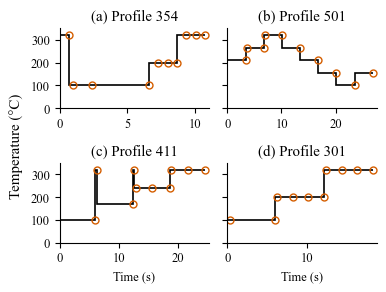

In [27]:
TIME_BASE_SECONDS = 0.140
HEATER_PROFILES = {
    354: [(320, 5), (100, 2), (100, 10), (100, 30), (200, 5),
          (200, 5), (200, 5), (320, 5), (320, 5), (320, 5)],
    501: [(210, 24), (265, 2), (265, 22), (320, 2), (320, 22),
          (265, 24), (210, 24), (155, 24), (100, 24), (155, 24)],
    411: [(100, 43), (320, 2), (170, 43), (320, 2), (240, 2),
          (240, 20), (240, 21), (320, 2), (320, 20), (320, 21)],
    301: [(100, 2), (100, 41), (200, 2), (200, 14), (200, 14),
          (200, 14), (320, 2), (320, 14), (320, 14), (320, 14)],
}
fig, axes = plt.subplots(2, 2, figsize=(4, 3), layout='constrained', sharey=True)
for panel, ax, (profile, schedule) in zip('abcd', axes.flat, HEATER_PROFILES.items()):
    schedule = np.asarray(schedule)
    temperatures = schedule[:, 0]
    edges = np.r_[0, np.cumsum(schedule[:, 1] * TIME_BASE_SECONDS)]
    ax.stairs(temperatures, edges, baseline=None, color='black', linewidth=1.2)
    ax.plot(edges[1:], temperatures, 'o', markerfacecolor='none',
            markeredgecolor='#D55E00', markersize=5)
    ax.set(xlim=(0, edges[-1] * 1.025), ylim=(0, 350),
           yticks=[0, 100, 200, 300],
           title=f'({panel}) Profile {profile}')
axes[1, 0].set(xlabel='Time (s)')
axes[1, 1].set(xlabel='Time (s)')
fig.supylabel('Temperature (°C)', x=0.05)
fig.tight_layout()
fig.savefig("figures/heater_profiles.png", dpi=300, bbox_inches='tight')
plt.show()

## 4. Adaptation functions

Only the ten log-resistance coordinates are adapted. With vapor pressure included,
its ten coordinates are appended unchanged before the final source-fitted scaling.

The scalar mean pools all cycles and heater steps for each sensor. Vector mean
subtracts a separate mean for each heater step. Vector mean-variance independently
standardizes each sensor's resistance using population standard deviations.

CORAL maps target resistance into source coordinates. **The ridge $10^{-3}$ is
applied in source-standardized resistance coordinates**. Sample covariance uses $n-1$. For row-vector observations the
transform is $(x-m_t)(C_t+\lambda I)^{-1/2}(C_s+\lambda I)^{1/2}+m_s$.
Inverse scaling restores source log-resistance coordinates before feature assembly
or fingerprint display. Those aligned values are transformed coordinates, not
new physical measurements.

In [7]:
def symmetric_matrix_power(matrix, exponent):
    """Raise a symmetric positive-definite matrix to a real power."""
    eigenvalues, eigenvectors = np.linalg.eigh(matrix)
    if np.any(eigenvalues <= 0):
        raise ValueError('Regularized covariance must be positive definite.')
    return (eigenvectors * eigenvalues ** exponent) @ eigenvectors.T


def coral_align(source_fit, target_fit, target_values):
    """Fit moments on source_fit/target_fit; map target_values to the source."""
    source_covariance = np.cov(source_fit, rowvar=False)
    target_covariance = np.cov(target_fit, rowvar=False)
    ridge = CORAL_RIDGE * np.eye(source_fit.shape[1])
    transform = (symmetric_matrix_power(target_covariance + ridge, -0.5)
                 @ symmetric_matrix_power(source_covariance + ridge, 0.5))
    return ((target_values - target_fit.mean(axis=0)) @ transform
            + source_fit.mean(axis=0))


def adapt_resistance(source, target, method):
    """Full-recording adaptation, returning source and target log coordinates."""
    if method == 'none':
        return source.copy(), target.copy()
    if method == 'scalar_mean':
        return source - source.mean(), target - target.mean()
    if method == 'vector_mean':
        return source - source.mean(axis=0), target - target.mean(axis=0)
    if method == 'mean_variance':
        return (StandardScaler().fit_transform(source),
                StandardScaler().fit_transform(target))
    if method == 'coral':
        scaler = StandardScaler().fit(source)
        aligned = coral_align(scaler.transform(source), scaler.transform(target),
                              scaler.transform(target))
        return source.copy(), scaler.inverse_transform(aligned)
    raise ValueError(f'Unknown method: {method}')


def make_pair_features(source_frame, target_frame, method, include_resistance, include_pressure):
    """Adapt resistance, append optional pressure, and fit scaling on the source."""
    source_parts, target_parts = [], []
    if include_resistance:
        source_r, target_r = adapt_resistance(
            source_frame[RESISTANCE_COLUMNS].to_numpy(),
            target_frame[RESISTANCE_COLUMNS].to_numpy(), method)
        source_parts.append(source_r)
        target_parts.append(target_r)
    if include_pressure:
        source_parts.append(source_frame[PRESSURE_COLUMNS].to_numpy())
        target_parts.append(target_frame[PRESSURE_COLUMNS].to_numpy())
    if not source_parts:
        raise ValueError('Include at least one feature group.')
    source_values, target_values = np.column_stack(source_parts), np.column_stack(target_parts)
    scaler = StandardScaler().fit(source_values)
    return scaler.transform(source_values), scaler.transform(target_values)

## 5. Supervised LDA projections — Figure 2

Fit a separate two-component LDA to each of sensors 0–3 using standardized
log resistance and all 37 substance labels. Category colors are used only for
display. The axes share plot limits but represent independently fitted coordinates.
Sensor 1 is rotated by 180° for display. Labels mark six selected substance centroids.

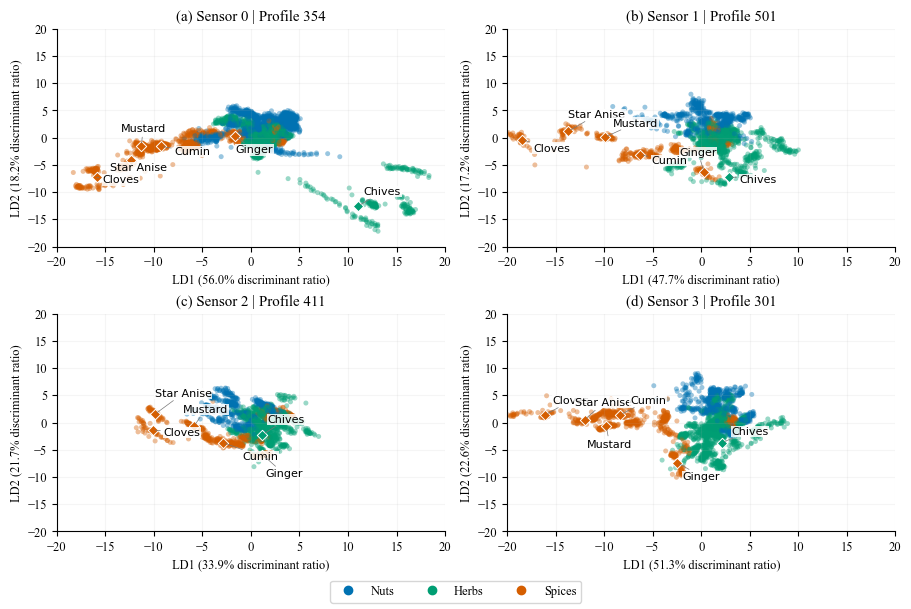

In [8]:
CATEGORY_COLORS = {'Nuts': '#0072B2', 'Herbs': '#009E73', 'Spices': '#D55E00'}
CENTROID_LABELS = ['Cloves', 'Star Anise', 'Mustard', 'Cumin', 'Ginger', 'Chives']
# Small fixed label offsets (points) keep names readable without affecting the data.
LABEL_OFFSETS = {
    0: [(4, -4), (-15, -8), (-15, 10), (10, -6), (0, -12), (4, 8)],
    1: [(8, -8), (0, 10), (6, 8), (8, -6), (-18, 12), (8, -4)],
    2: [(8, -4), (0, 13), (-8, 10), (14, -12), (2, -16), (4, 9)],
    3: [(5, 8), (-7, 10), (-14, -15), (7, 8), (4, -12), (7, 6)],
}
lda_projections = {}
fig, axes = plt.subplots(2, 2, figsize=(9, 6), layout='constrained',
                         sharex=True, sharey=True)
for panel, sensor, ax in zip('abcd', range(4), axes.flat):
    frame = features.loc[features['sensor_index'].eq(sensor)]
    x = StandardScaler().fit_transform(frame[RESISTANCE_COLUMNS])
    lda = LinearDiscriminantAnalysis(n_components=2, solver='svd')
    points = lda.fit_transform(x, frame['substance'])
    if sensor == 1:
        points = -points
    lda_projections[sensor] = points
    colors = frame['substance'].map(class_categories).map(CATEGORY_COLORS).to_numpy()
    order = np.random.default_rng(42).permutation(len(frame))
    ax.scatter(points[order, 0], points[order, 1], c=colors[order],
               s=13, alpha=.4, linewidths=0)
    for label, offset in zip(CENTROID_LABELS, LABEL_OFFSETS[sensor]):
        center = points[frame['substance'].eq(label)].mean(axis=0)
        ax.scatter(*center, marker='D', s=28, color=CATEGORY_COLORS[class_categories[label]],
                   edgecolors='white', linewidths=.7, zorder=4)
        ax.annotate(label, center, xytext=offset, textcoords='offset points',
                    fontsize=8, fontfamily='DejaVu Sans', zorder=5,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=.85, pad=.5),
                    arrowprops=dict(arrowstyle='-', color='#777777', lw=.5))
    ratios = 100 * lda.explained_variance_ratio_
    ax.set(xlabel=f'LD1 ({ratios[0]:.1f}% discriminant ratio)',
           ylabel=f'LD2 ({ratios[1]:.1f}% discriminant ratio)',
           title=f'({panel}) Sensor {sensor} | Profile {PROFILES[sensor]}')
    ax.tick_params(labelbottom=True, labelleft=True)
    ax.grid(alpha=.12)
    ax.set_xlim([-20,20])
    ax.set_ylim([-20,20])
handles = [Line2D([], [], marker='o', linestyle='', color=color, label=category)
           for category, color in CATEGORY_COLORS.items()]
fig.legend(handles=handles, loc='outside lower center', ncol=3)
fig.savefig("figures/sensor_pairs_lda.png", dpi=300, bbox_inches='tight')
plt.show()

## 6. Paired-sensor fingerprints — Figure 3

Display Cumin and Lavender for sensor 1 (source) and sensor 5 (target), which share
profile 501. Fit each adaptation using **all classes and cycles**, then select these
two classes for display. Faint lines are individual cycles; bold lines are means;
shaded bands are ±1 population SD. Raw and CORAL columns use identical vertical limits.

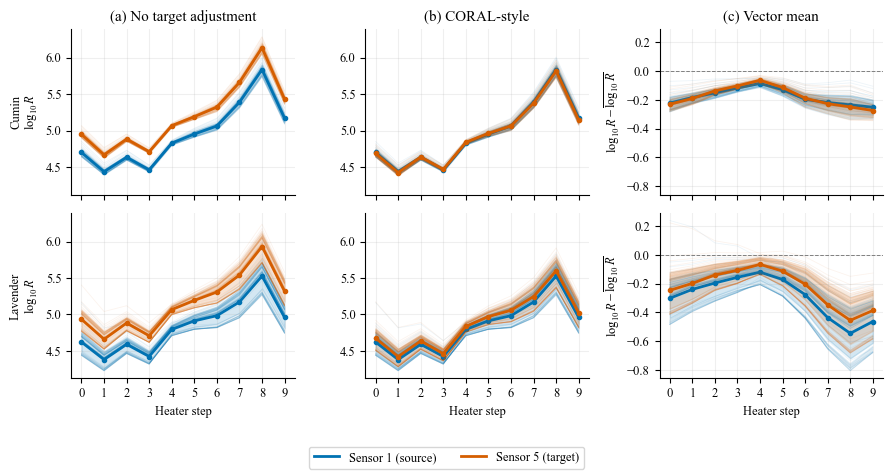

In [9]:
source_frame = features.loc[features['sensor_index'].eq(1)]
target_frame = features.loc[features['sensor_index'].eq(5)]
source_r = source_frame[RESISTANCE_COLUMNS].to_numpy()
target_r = target_frame[RESISTANCE_COLUMNS].to_numpy()
fingerprint_classes = ('Cumin', 'Lavender')
fig, axes = plt.subplots(2, 3, figsize=(9, 5), sharex=True, sharey='col')
for column, method in enumerate(('none', 'coral', 'vector_mean')):
    source_values, target_values = adapt_resistance(source_r, target_r, method)
    for row, substance in enumerate(fingerprint_classes):
        ax = axes[row, column]
        for frame, values, color in ((source_frame, source_values, '#0072B2'),
                                      (target_frame, target_values, '#D55E00')):
            group = values[frame['substance'].eq(substance).to_numpy()]
            mean, sd = group.mean(axis=0), group.std(axis=0)
            ax.plot(range(10), group.T, color=color, alpha=.07, linewidth=.6)
            ax.fill_between(range(10), mean - sd, mean + sd, color=color, alpha=.17)
            ax.plot(range(10), mean, color=color, linewidth=2, marker='o', markersize=3)
        if row == 0:
            ax.set_title(f'({"abc"[column]}) {METHOD_NAMES[method]}')
        if column == 0:
            ax.set_ylabel(f'{substance}\n' + r'$\log_{10} R$')
        elif column == 2:
            ax.set_ylabel(r'$\log_{10} R - \overline{\log_{10} R}$')
            ax.axhline(0, color='gray', linewidth=.7, linestyle='--')
        if row == 1:
            ax.set_xlabel('Heater step')
        ax.set_xticks(range(10))
        ax.grid(alpha=.2)
limits = [axes[0, column].get_ylim() for column in (0, 1)]
common_limits = (min(low for low, high in limits), max(high for low, high in limits))
for column in (0, 1):
    axes[0, column].set_ylim(common_limits)
fig.tight_layout(rect=(0, .08, 1, 0.95))
fig.legend(handles=[Line2D([], [], color=color, lw=2, label=label)
                    for color, label in (('#0072B2', 'Sensor 1 (source)'),
                                          ('#D55E00', 'Sensor 5 (target)'))],
           loc='outside lower center', ncol=2, frameon=True)
plt.show()
fig.savefig("figures/fingerprints.png", dpi=300, bbox_inches='tight')

## 7. Transfer ablation — Table III

Train LDA (`solver='svd'`, empirical source class priors, no tuning) on one sensor
and evaluate on its paired sensor. Evaluate both directions of all four pairs.
Full-recording adaptation estimates each sensor's statistics using all its cycles.

The table contains a pressure-only control, then resistance alone and resistance
plus pressure for each of the five compensation choices: **11 configurations × 8
directions = 88 fits**. Retain direction scores and CORAL predictions for the next
table. Accuracy weights cycles equally; balanced accuracy weights the 37 class
recalls equally. Report mean and sample SD over directions, in percent.

In [10]:
CONFIGURATIONS = [('none', False, True)] + [
    (method, True, pressure)
    for method in METHOD_NAMES for pressure in (False, True)
]
ablation_rows, coral_predictions = [], []
with threadpool_limits(limits=1):
    for source, target in DIRECTIONS:
        train = features.loc[features['sensor_index'].eq(source)]
        test = features.loc[features['sensor_index'].eq(target)]
        ys, yt = train['substance'].to_numpy(), test['substance'].to_numpy()
        for method, resistance, pressure in CONFIGURATIONS:
            xs, xt = make_pair_features(train, test, method, resistance, pressure)
            model = LinearDiscriminantAnalysis(solver='svd').fit(xs, ys)
            source_prediction, prediction = model.predict(xs), model.predict(xt)
            ablation_rows.append(dict(
                source=source, target=target, method=method,
                resistance=resistance, pressure=pressure,
                train_accuracy=accuracy_score(ys, source_prediction),
                train_balanced_accuracy=balanced_accuracy_score(ys, source_prediction),
                accuracy=accuracy_score(yt, prediction),
                balanced_accuracy=balanced_accuracy_score(yt, prediction),
            ))
            if method == 'coral' and pressure:
                detail = test[['source_file', 'sensor_index', 'cycle_id', 'substance']].copy()
                detail['source'] = source
                detail['prediction'] = prediction
                coral_predictions.append(detail)
ablation_scores = pd.DataFrame(ablation_rows)
coral_predictions = pd.concat(coral_predictions, ignore_index=True)
assert len(ablation_scores) == 88


def mean_sd_percent(values):
    """Format mean and sample SD in percent."""
    return f'{100 * values.mean():.1f} ({100 * values.std(ddof=1):.1f})'


ablation_table_rows = []
for method, resistance, pressure in CONFIGURATIONS:
    scores = ablation_scores.loc[
        ablation_scores['method'].eq(method)
        & ablation_scores['resistance'].eq(resistance)
        & ablation_scores['pressure'].eq(pressure)]
    ablation_table_rows.append({
        'Compensation': 'None' if method == 'none' else METHOD_NAMES[method],
        'Log resistance': '✓' if resistance else '×',
        'Log vapor pressure': '✓' if pressure else '×',
        'Target accuracy (%)': mean_sd_percent(scores['accuracy']),
        'Target balanced accuracy (%)': mean_sd_percent(scores['balanced_accuracy']),
    })
ablation_table = pd.DataFrame(ablation_table_rows)
display(ablation_table.style.hide(axis='index'))

source_table = []
for pressure in (False, True):
    scores = ablation_scores.loc[ablation_scores['method'].eq('none')
                                 & ablation_scores['resistance']
                                 & ablation_scores['pressure'].eq(pressure)]
    source_table.append({'Source training features': 'Resistance + pressure' if pressure else 'Resistance',
                         'Accuracy (%)': mean_sd_percent(scores['train_accuracy']),
                         'Balanced accuracy (%)': mean_sd_percent(scores['train_balanced_accuracy'])})
display(pd.DataFrame(source_table).style.hide(axis='index'))

Compensation,Log resistance,Log vapor pressure,Target accuracy (%),Target balanced accuracy (%)
None,×,✓,14.2 (1.4),13.6 (1.6)
None,✓,×,30.6 (9.4),33.8 (9.8)
None,✓,✓,42.6 (10.0),47.0 (10.0)
CORAL-style,✓,×,58.0 (3.5),61.7 (2.9)
CORAL-style,✓,✓,67.0 (3.8),71.2 (3.0)
Vector mean-variance,✓,×,55.6 (4.5),59.3 (4.0)
Vector mean-variance,✓,✓,65.7 (4.9),69.8 (3.9)
Vector mean,✓,×,54.3 (4.5),57.7 (4.0)
Vector mean,✓,✓,64.5 (4.7),68.4 (4.0)
Scalar mean,✓,×,34.6 (10.7),37.6 (10.9)


Source training features,Accuracy (%),Balanced accuracy (%)
Resistance,75.7 (2.6),80.3 (1.8)
Resistance + pressure,81.8 (3.1),85.9 (2.4)


## 8. Recall for selected substances — Table IV

Use the CORAL predictions with log resistance and log vapor pressure from the
preceding experiment. Calculate each substance's recall separately for each
direction, then report the mean, sample SD, and range across the eight directions
for ten selected substances.

In [11]:
coral_predictions['correct'] = coral_predictions['substance'].eq(coral_predictions['prediction'])
recall_by_direction = coral_predictions.groupby(['substance', 'source', 'sensor_index']).agg(
    recall=('correct', 'mean'), correct=('correct', 'sum'), cycles=('correct', 'size')).reset_index()
assert recall_by_direction.groupby('substance').size().eq(8).all()
recall_summary = recall_by_direction.groupby('substance')['recall'].agg(
    mean='mean', sd='std', minimum='min', maximum='max')
SELECTED_SUBSTANCES = ['Mustard', 'Star Anise', 'Ginger', 'Lavender', 'Almond',
                       'Peanuts', 'Oregano', 'Lonicera', 'Vervain', 'Eupatorium']
selected_recall_table = pd.DataFrame({
    'Mean (SD) %': [f'{100 * recall_summary.loc[label, "mean"]:.1f} '
                   f'({100 * recall_summary.loc[label, "sd"]:.1f})'
                   for label in SELECTED_SUBSTANCES],
    'Range %': [f'{100 * recall_summary.loc[label, "minimum"]:.1f}–'
                f'{100 * recall_summary.loc[label, "maximum"]:.1f}'
                for label in SELECTED_SUBSTANCES],
}, index=pd.Index(SELECTED_SUBSTANCES, name='Substance'))
display(selected_recall_table)

,Mean (SD) %,Range %
Substance,,
Mustard,98.8 (3.3),90.6–100.0
Star Anise,98.1 (1.9),93.8–100.0
Ginger,97.7 (2.2),93.4–100.0
Lavender,96.2 (4.1),89.4–99.0
Almond,85.0 (33.2),4.3–100.0
Peanuts,74.8 (22.4),47.1–100.0
Oregano,57.0 (37.5),6.2–97.4
Lonicera,20.7 (12.5),4.1–38.2
Vervain,17.7 (14.5),4.0–44.1


## 9. Reduced adaptation coverage — Figure 4

Keep the source scaler and the source LDA fixed, trained on all 37 classes with
resistance and pressure features. Restrict **only the resistance adaptation moments**
to a selected set of substances on both sensors. Every available cycle in those
classes contributes to the moments with its observed weight. Evaluate on all target
classes, and separately calculate mean recall over classes omitted from adaptation.

Use the first 5, 10, 15, 20, 25, 30, 35, and 37 classes of each of 30 random
permutations (seed 42), sharing the exact same subsets across methods and directions.
Sort the chosen class names for recording, not for drawing the random subsets.
Full coverage is evaluated once because all permutations then contain the same set.
Labels select this controlled coverage condition; the adaptation itself uses moments
of the selected measurements, without class-specific alignment.

In fixed source-standardized coordinates, vector mean adds the difference of subset
means and vector mean-variance additionally matches subset population SDs. Scalar
mean is calculated in log-resistance units and then converted back through the source
scales. CORAL uses the same standardized-coordinate ridge as above. This leaves the
source model fixed and reproduces full-recording adaptation at 37 classes.

In [12]:
def adapt_from_subset(source_fit, target_fit, target_values, method, source_scale):
    """Map target resistance into a fixed source-standardized feature space."""
    source_mean, target_mean = source_fit.mean(axis=0), target_fit.mean(axis=0)
    if method == 'vector_mean':
        return target_values - target_mean + source_mean
    if method == 'mean_variance':
        source_sd, target_sd = source_fit.std(axis=0), target_fit.std(axis=0)
        source_sd = np.where(source_sd == 0, 1., source_sd)
        target_sd = np.where(target_sd == 0, 1., target_sd)
        return (target_values - target_mean) * (source_sd / target_sd) + source_mean
    if method == 'scalar_mean':
        scalar_offset = np.mean((source_mean - target_mean) * source_scale)
        return target_values + scalar_offset / source_scale
    if method == 'coral':
        return coral_align(source_fit, target_fit, target_values)
    raise ValueError(f'Unknown coverage method: {method}')


CLASS_COUNTS = (5, 10, 15, 20, 25, 30, 35, 37)
REPEATS, SEED = 30, 42
COVERAGE_METHODS = ('scalar_mean', 'vector_mean', 'mean_variance', 'coral')
rng = np.random.default_rng(SEED)
permutations = [rng.permutation(classes) for _ in range(REPEATS)]
adaptation_subsets = [
    {'n_classes': count, 'repeat': repeat, 'classes': sorted(order[:count].tolist())}
    for count in CLASS_COUNTS for repeat, order in enumerate(permutations)
    if count < len(classes) or repeat == 0
]
print(f'{len(adaptation_subsets)} subsets × {len(DIRECTIONS)} directions × '
      f'{len(COVERAGE_METHODS)} methods = '
      f'{len(adaptation_subsets) * len(DIRECTIONS) * len(COVERAGE_METHODS):,} evaluations')

211 subsets × 8 directions × 4 methods = 6,752 evaluations


In [13]:
coverage_rows = []
coverage_started = time.perf_counter()
with threadpool_limits(limits=1):
    for source, target in DIRECTIONS:
        train = features.loc[features['sensor_index'].eq(source)]
        test = features.loc[features['sensor_index'].eq(target)]
        ys, yt = train['substance'].to_numpy(), test['substance'].to_numpy()
        columns = RESISTANCE_COLUMNS + PRESSURE_COLUMNS
        scaler = StandardScaler().fit(train[columns])
        xs, xt = scaler.transform(train[columns]), scaler.transform(test[columns])
        model = LinearDiscriminantAnalysis(solver='svd').fit(xs, ys)
        class_masks = [yt == label for label in classes]
        for subset in adaptation_subsets:
            count, repeat, chosen = subset['n_classes'], subset['repeat'], subset['classes']
            source_mask, target_mask = np.isin(ys, chosen), np.isin(yt, chosen)
            included = np.isin(classes, chosen)
            for method in COVERAGE_METHODS:
                aligned = adapt_from_subset(
                    xs[source_mask, :10], xt[target_mask, :10], xt[:, :10],
                    method, scaler.scale_[:10])
                prediction = model.predict(np.column_stack([aligned, xt[:, 10:]]))
                recalls = np.array([np.mean(prediction[mask] == label)
                                    for label, mask in zip(classes, class_masks)])
                coverage_rows.append(dict(
                    source=source, target=target, method=method,
                    n_classes=count, repeat=repeat,
                    n_source_adaptation=int(source_mask.sum()),
                    n_target_adaptation=int(target_mask.sum()),
                    balanced_accuracy=recalls.mean(),
                    omitted_recall=recalls[~included].mean() if count < len(classes) else np.nan))
        print(f'Completed {source} → {target} ({time.perf_counter() - coverage_started:.1f} s elapsed)')
coverage_scores = pd.DataFrame(coverage_rows)
assert len(coverage_scores) == 6_752

Completed 0 → 4 (4.8 s elapsed)
Completed 4 → 0 (9.4 s elapsed)
Completed 1 → 5 (11.2 s elapsed)
Completed 5 → 1 (13.1 s elapsed)
Completed 2 → 6 (15.0 s elapsed)
Completed 6 → 2 (16.9 s elapsed)
Completed 3 → 7 (19.9 s elapsed)
Completed 7 → 3 (22.4 s elapsed)


Average the eight directions **within each trial first**, then plot the mean and
10th–90th percentile band over the 30 subset trials. The bands describe sensitivity
to the selected adaptation classes; they are not confidence intervals. At full
coverage there is one estimate and no omitted-class score. Wider omitted-class
bands near full coverage also reflect the smaller number of classes being scored.

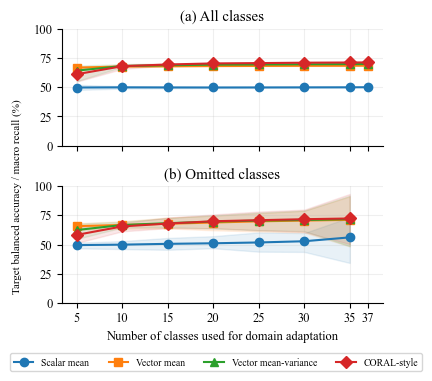

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(4, 4), sharex=True)
for ax, metric, title in zip(axes, ('balanced_accuracy', 'omitted_recall'),
                             ('(a) All classes', '(b) Omitted classes')):
    for method, marker in zip(COVERAGE_METHODS, ('o', 's', '^', 'D')):
        trials = coverage_scores.loc[coverage_scores['method'].eq(method)].groupby(
            ['n_classes', 'repeat'])[metric].mean().dropna()
        grouped = trials.groupby(level='n_classes')
        average = grouped.mean() * 100
        low, high = grouped.quantile(.1) * 100, grouped.quantile(.9) * 100
        line, = ax.plot(average.index, average, marker=marker, label=METHOD_NAMES[method])
        repeated = grouped.size().gt(1)
        ax.fill_between(average.index[repeated], low[repeated], high[repeated],
                         color=line.get_color(), alpha=.1)
    ax.set(title=title, ylim=(0, 100), xticks=CLASS_COUNTS)
    ax.grid(alpha=.2)
axes[1].set_xlabel('Number of classes used for domain adaptation')

fig.supylabel('Target balanced accuracy / macro recall (%)', x=0.04, fontsize=8)
fig.tight_layout(rect=(0, .1, 1, 1))
#fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=4)
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', bbox_to_anchor=(0.55, 0.05), ncol=4, frameon=True, fontsize=7)
fig.savefig("figures/domain_adaptation.png", dpi=300, bbox_inches='tight')

plt.show()